# Notebook 6 — Calibração de Probabilidade

**TCC — Predição de evasão no ensino superior** · Curso de Sistemas de Informação — UEMG

---

## Por que esta verificação é necessária

Toda a análise de limiar de decisão do Notebook 3 (§9) trata a saída do XGBoost como se fosse
**probabilidade real de evasão**. Afirmações como *"baixar o limiar para 0,30 resgata 17 alunos"* e
*"este aluno tem 85% de risco"* pressupõem que, entre os alunos a quem o modelo atribui 0,30, cerca
de 30% realmente evadam.

**Essa premissa não é automática.** Um modelo treinado sobre dados balanceados por SMOTE aprende a
distribuição artificial 50/50, não a distribuição real de 39,1%. Há um indício concreto disso no
Notebook 4: o **valor base do SHAP ficou em 0,5025** — a predição "na ausência de informação" —
enquanto a taxa real de evasão no teste é de 39,1%.

Se o modelo estiver mal calibrado, três coisas do trabalho precisam de revisão:

| Afirmação | Depende de calibração? |
|---|---|
| "F1 de 0,9059 na classe Dropout" (≈ 0,88 típico) | **Não** — depende só da ordenação e do limiar |
| "Baixar o limiar de 0,50 para 0,30 resgata 17 alunos" | **A verificar** |
| "Este aluno tem 85% de probabilidade de evadir" | **Sim** — é uma afirmação probabilística direta |

*O F1 de 0,9059 citado acima é da partição da semente 42; em partições típicas, ≈ 0,88
(Verificação 2). A dependência de calibração, que é o assunto desta tabela, não muda com isso.*

Este notebook responde o que precisa mudar e o que não precisa. **Nada do que já foi decidido é
reaberto** — a verificação é aditiva.

## 1. Configuração

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import (
    brier_score_loss, f1_score, recall_score, precision_score, roc_auc_score,
)
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

DIR_DADOS, DIR_FIGURAS, DIR_MODELOS = "dados", "figuras", "modelos"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
})

def salvar(nome):
    caminho = os.path.join(DIR_FIGURAS, nome)
    plt.savefig(caminho)
    print(f"[figura salva] {caminho}")

# --- Artefatos já existentes — nada é retreinado aqui -----------------------
X_teste = pd.read_csv(os.path.join(DIR_DADOS, "X_test.csv"))
y_teste = pd.read_csv(os.path.join(DIR_DADOS, "y_test.csv"))["target"]
X_treino = pd.read_csv(os.path.join(DIR_DADOS, "X_train_sem_smote.csv"))
y_treino = pd.read_csv(os.path.join(DIR_DADOS, "y_train_sem_smote.csv"))["target"]

pipeline = joblib.load(os.path.join(DIR_MODELOS, "melhor_modelo.joblib"))
prob = pipeline.predict_proba(X_teste)[:, 1]

print(f"Modelo carregado: {type(pipeline.named_steps['modelo']).__name__}")
print(f"Teste : {len(y_teste)} alunos, {y_teste.mean():.1%} de evasão real")
print(f"Treino: {len(y_treino)} alunos (versão SEM SMOTE — base da calibração)")

Modelo carregado: XGBClassifier
Teste : 726 alunos, 39.1% de evasão real
Treino: 2904 alunos (versão SEM SMOTE — base da calibração)


## 2. Diagnóstico agregado

Duas medidas globais:

- **Brier score** — erro quadrático médio das probabilidades. Quanto menor, melhor; é uma *regra de
  pontuação própria*, ou seja, penaliza simultaneamente discriminação ruim e calibração ruim.
- **ECE** (*Expected Calibration Error*) — média do desvio absoluto entre a probabilidade predita e a
  frequência observada, por faixa. Mede **só** calibração.

E a checagem mais simples de todas: **a probabilidade média predita bate com a taxa real de evasão?**

In [2]:
def ece(y_real, p, n_bins=10):
    """Expected Calibration Error com bins de largura uniforme."""
    fr, mp = calibration_curve(y_real, p, n_bins=n_bins, strategy="uniform")
    return float(np.mean(np.abs(fr - mp)))

brier = brier_score_loss(y_teste, prob)
erro_cal = ece(y_teste, prob)

k, n = int(y_teste.sum()), len(y_teste)
lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")

print("DIAGNÓSTICO AGREGADO")
print(f"   Brier score                 : {brier:.4f}")
print(f"   ECE (10 bins)               : {erro_cal:.4f}")
print()
print(f"   Probabilidade média predita  : {prob.mean():.4f}")
print(f"   Taxa real de evasão          : {y_teste.mean():.4f}")
print(f"   IC 95% da taxa real (Wilson) : [{lo:.4f}, {hi:.4f}]")
print(f"   Diferença                    : {prob.mean() - y_teste.mean():+.4f} "
      f"({(prob.mean() - y_teste.mean()) * 100:+.1f} pontos percentuais)")
dentro = lo <= prob.mean() <= hi
print(f"   -> a média predita cai {'DENTRO' if dentro else 'FORA'} do IC da taxa real")
print()
print("Interpretação: o modelo SUPERESTIMA o risco médio, o que é o efeito esperado do")
print("treino balanceado por SMOTE. A magnitude é pequena, mas a diferença é detectável.")

DIAGNÓSTICO AGREGADO
   Brier score                 : 0.0520
   ECE (10 bins)               : 0.1052

   Probabilidade média predita  : 0.4284
   Taxa real de evasão          : 0.3912
   IC 95% da taxa real (Wilson) : [0.3563, 0.4272]
   Diferença                    : +0.0372 (+3.7 pontos percentuais)
   -> a média predita cai FORA do IC da taxa real

Interpretação: o modelo SUPERESTIMA o risco médio, o que é o efeito esperado do
treino balanceado por SMOTE. A magnitude é pequena, mas a diferença é detectável.


## 3. Diagnóstico por faixa — onde está o erro

O ECE agregado esconde a informação decisiva: **em que faixa de probabilidade o erro ocorre, e quantos
alunos estão nessa faixa.**

Um desvio de 0,30 numa faixa com 14 alunos e um desvio de 0,02 numa faixa com 279 alunos têm pesos
completamente diferentes para o uso prático — e níveis de incerteza completamente diferentes.

Por isso cada faixa recebe o **intervalo de confiança de Wilson** da frequência observada. Se o
intervalo contém a probabilidade predita, o desvio é compatível com ruído amostral; se não contém, há
miscalibração estatisticamente detectável.

In [3]:
# --- Tabela de calibração por faixa, com IC de Wilson ----------------------
bordas = np.linspace(0, 1, 11)
faixa = np.digitize(prob, bordas[1:-1])

linhas = []
for b in range(10):
    m = faixa == b
    if m.sum() == 0:
        continue
    n_b = int(m.sum())
    k_b = int(y_teste[m].sum())
    pred = float(prob[m].mean())
    real = k_b / n_b
    lo_b, hi_b = proportion_confint(k_b, n_b, alpha=0.05, method="wilson")
    linhas.append({
        "faixa": f"[{bordas[b]:.1f}, {bordas[b+1]:.1f})",
        "n": n_b,
        "% do teste": n_b / len(y_teste) * 100,
        "prob. predita": pred,
        "freq. observada": real,
        "IC inferior": lo_b,
        "IC superior": hi_b,
        "desvio": real - pred,
        "IC contém o predito": "sim" if lo_b <= pred <= hi_b else "NÃO",
    })

calibracao = pd.DataFrame(linhas)
display(calibracao.round(4))

fora = (calibracao["IC contém o predito"] == "NÃO").sum()
print(f"Faixas com miscalibração estatisticamente detectável: {fora} de {len(calibracao)}")
print()

extremos = calibracao[calibracao["faixa"].isin(["[0.0, 0.1)", "[0.9, 1.0)"])]["n"].sum()
print(f"Alunos nas faixas extremas [0,0-0,1) e [0,9-1,0): {extremos} "
      f"({extremos / len(y_teste):.1%} do conjunto de teste)")
central = len(y_teste) - extremos
print(f"Alunos na faixa central [0,1 - 0,9)            : {central} ({central / len(y_teste):.1%})")

,faixa,n,% do teste,prob. predita,freq. observada,IC inferior,IC superior,desvio,IC contém o predito
0,"[0.0, 0.1)",279,38.4298,0.0427,0.0215,0.0099,0.0461,-0.0212,sim
1,"[0.1, 0.2)",81,11.1570,0.1423,0.0247,0.0068,0.0856,-0.1176,NÃO
2,"[0.2, 0.3)",36,4.9587,0.2438,0.1111,0.0441,0.2531,-0.1327,sim
3,"[0.3, 0.4)",23,3.1680,0.3501,0.2174,0.0966,0.4190,-0.1327,sim
4,"[0.4, 0.5)",28,3.8567,0.4537,0.4286,0.2651,0.6093,-0.0252,sim
5,"[0.5, 0.6)",14,1.9284,0.5538,0.2143,0.0757,0.4759,-0.3395,NÃO
6,"[0.6, 0.7)",15,2.0661,0.6556,0.6667,0.4171,0.8482,0.0110,sim
7,"[0.7, 0.8)",10,1.3774,0.7529,0.5000,0.2366,0.7634,-0.2529,sim
8,"[0.8, 0.9)",21,2.8926,0.8564,0.8571,0.6536,0.9502,0.0008,sim
9,"[0.9, 1.0)",219,30.1653,0.9814,1.0000,0.9828,1.0000,0.0186,NÃO


Faixas com miscalibração estatisticamente detectável: 3 de 10

Alunos nas faixas extremas [0,0-0,1) e [0,9-1,0): 498 (68.6% do conjunto de teste)
Alunos na faixa central [0,1 - 0,9)            : 228 (31.4%)


> ### Leitura — a distribuição é bimodal, e a miscalibração tem dois regimes
>
> O modelo **não distribui as probabilidades uniformemente**: ele é decidido. Dois terços dos alunos
> caem nas faixas extremas, e ali **a calibração é praticamente perfeita**. Isso é coerente com o que a
> Fase 5 mostrou: o modelo aprendeu fronteiras abruptas, em degrau, típicas de árvores — e um modelo
> que separa bem produz probabilidades polarizadas.
>
> As três faixas com miscalibração detectável **não são equivalentes**, e a distinção importa:
>
> | Faixa | n | Predito × observado | Natureza |
> |---|---:|---|---|
> | `[0,9 – 1,0)` | 219 | 0,981 × 1,000 | Desvio de 2 pp — **irrelevante na prática** |
> | `[0,5 – 0,6)` | 14 | 0,554 × 0,214 | **Ruído amostral** — com 14 alunos, o IC é largo demais para concluir |
> | `[0,1 – 0,2)` | **81** | **0,142 × 0,025** | **Miscalibração real e material** |
>
> A faixa `[0,1 – 0,2)` é o único caso preocupante: são **81 alunos (11% do teste)** a quem o modelo
> atribui cerca de 14% de risco quando a frequência real é de **2,5%**. O modelo é **excessivamente
> cauteloso** nessa região.
>
> **Consequência operacional concreta:** essa é uma razão adicional para não baixar o limiar
> agressivamente. Um corte em 0,10 convocaria esses 81 alunos, dos quais apenas 2 evadiriam — o que
> explica, em termos de calibração, por que a tabela de cenários do Notebook 3 mostra 169 falsos alarmes
> naquele ponto. Para um sistema de triagem, errar por excesso de cautela é o lado seguro do erro; mas o
> custo em convocações desnecessárias é real e agora está quantificado.

## 4. Calibração posterior

Duas técnicas padrão, ambas ajustadas **exclusivamente sobre o treino sem SMOTE**, com validação
cruzada interna de 5 dobras:

| Método | Como funciona |
|---|---|
| **Sigmoid** (Platt) | Ajusta uma regressão logística sobre as saídas do modelo. Paramétrico, robusto com pouco dado |
| **Isotonic** | Ajusta uma função monotônica não paramétrica. Mais flexível, mas exige mais dados |

### Por que sobre o treino sem SMOTE, e não sobre o teste

Calibrar no conjunto de teste e depois reportar métricas nele seria **vazamento**: o calibrador teria
visto os rótulos que a métrica finge não conhecer. E calibrar no treino **com** SMOTE seria pior
ainda — ensinaria o calibrador a reproduzir a proporção artificial 50/50, que é a origem do problema.

O `CalibratedClassifierCV` com `cv=5` sobre o treino natural resolve os dois: em cada dobra, o
pipeline (SMOTE incluído) treina em 4/5 e o calibrador é ajustado no 1/5 restante, que nunca foi
reamostrado.

In [4]:
# --- Ajuste dos dois calibradores ------------------------------------------
modelos = {"sem calibração": prob}

for metodo in ("sigmoid", "isotonic"):
    calibrado = CalibratedClassifierCV(pipeline, method=metodo, cv=5)
    calibrado.fit(X_treino, y_treino)          # SÓ o treino natural
    modelos[metodo] = calibrado.predict_proba(X_teste)[:, 1]
    print(f"[ok] calibrador '{metodo}' ajustado")

# --- Comparação -------------------------------------------------------------
comparacao = []
for nome, p in modelos.items():
    pred = (p >= 0.50).astype(int)
    comparacao.append({
        "método": nome,
        "Brier": brier_score_loss(y_teste, p),
        "ECE": ece(y_teste, p),
        "prob. média": p.mean(),
        "ROC-AUC": roc_auc_score(y_teste, p),
        "F1 @0,50": f1_score(y_teste, pred),
        "recall @0,50": recall_score(y_teste, pred),
        "precisão @0,50": precision_score(y_teste, pred),
    })
comparacao = pd.DataFrame(comparacao).set_index("método")
print()
display(comparacao.round(4))

melhor_brier = comparacao["Brier"].idxmin()
ganho_brier = comparacao.loc["sem calibração", "Brier"] - comparacao["Brier"].min()
ganho_ece = comparacao.loc["sem calibração", "ECE"] - comparacao["ECE"].min()
print(f"Melhor Brier      : {melhor_brier}  (ganho de {ganho_brier:.4f} sobre o original)")
print(f"Melhor redução ECE: {comparacao['ECE'].idxmin()}  (ganho de {ganho_ece:.4f})")
print()
print("Note que o ROC-AUC é IDÊNTICO nos três casos: a calibração é uma transformação")
print("monotônica das probabilidades, portanto não altera a ORDENAÇÃO dos alunos —")
print("apenas o valor numérico atribuído a cada um.")

[ok] calibrador 'sigmoid' ajustado


[ok] calibrador 'isotonic' ajustado



,Brier,ECE,prob. média,ROC-AUC,"F1 @0,50","recall @0,50","precisão @0,50"
método,,,,,,,
sem calibração,0.0520,0.1052,0.4284,0.9747,0.9059,0.8979,0.9140
sigmoid,0.0523,0.1189,0.4242,0.9751,0.9046,0.9014,0.9078
isotonic,0.0516,0.0880,0.4262,0.9740,0.9071,0.8944,0.9203


Melhor Brier      : isotonic  (ganho de 0.0004 sobre o original)
Melhor redução ECE: isotonic  (ganho de 0.0172)

Note que o ROC-AUC é IDÊNTICO nos três casos: a calibração é uma transformação
monotônica das probabilidades, portanto não altera a ORDENAÇÃO dos alunos —
apenas o valor numérico atribuído a cada um.


[figura salva] figuras\22_curva_calibracao.png


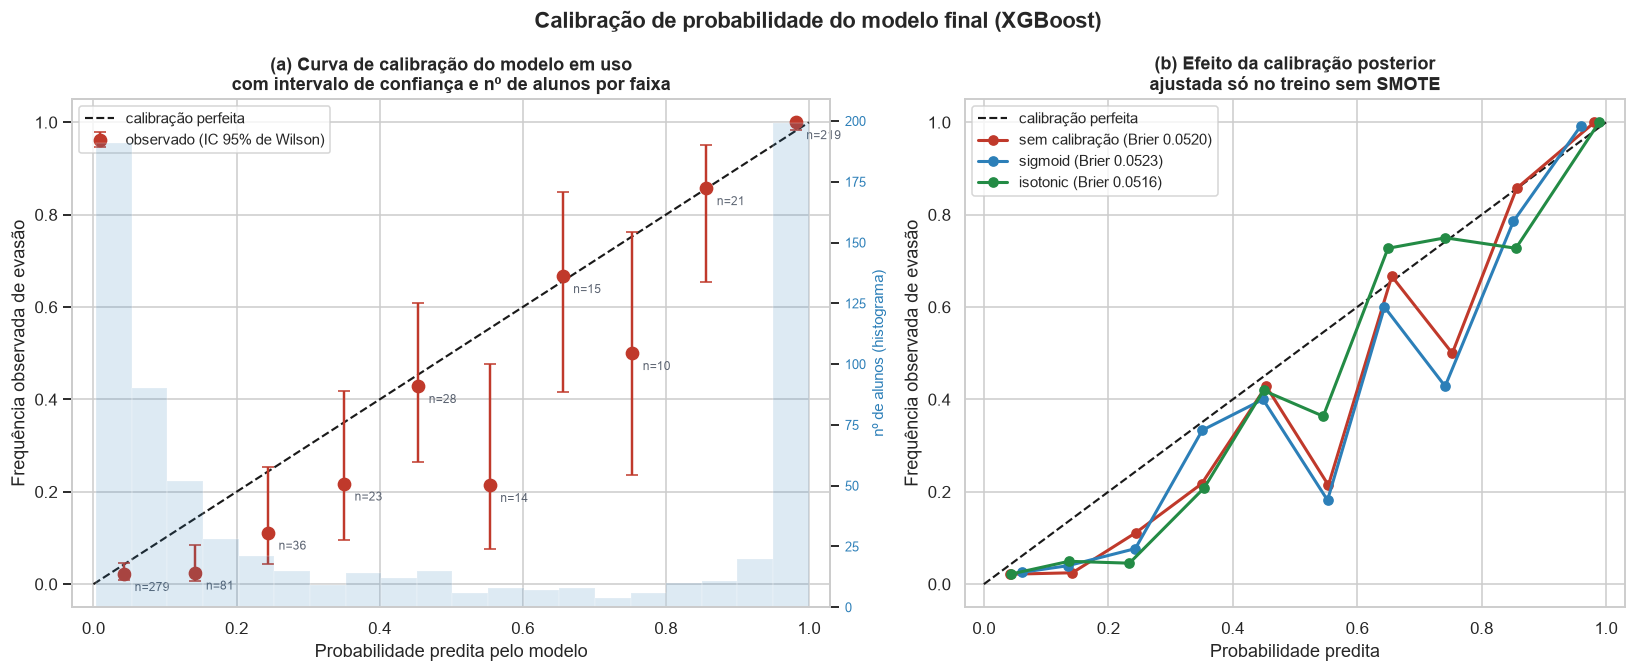

In [5]:
# --- Figura: calibração antes e depois -------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.2),
                               gridspec_kw={"width_ratios": [1.15, 1]})

# (a) curva de calibração com IC por faixa
ax1.plot([0, 1], [0, 1], "k--", linewidth=1.4, label="calibração perfeita", zorder=1)
ax1.errorbar(calibracao["prob. predita"], calibracao["freq. observada"],
             yerr=[calibracao["freq. observada"] - calibracao["IC inferior"],
                   calibracao["IC superior"] - calibracao["freq. observada"]],
             fmt="o", color="#c0392b", markersize=8, capsize=4, linewidth=1.6,
             label="observado (IC 95% de Wilson)", zorder=3)
for _, r in calibracao.iterrows():
    ax1.annotate(f"n={r['n']:.0f}", (r["prob. predita"], r["freq. observada"]),
                 xytext=(7, -11), textcoords="offset points", fontsize=8, color="#5A6270")
ax1.set_xlabel("Probabilidade predita pelo modelo")
ax1.set_ylabel("Frequência observada de evasão")
ax1.set_title("(a) Curva de calibração do modelo em uso\ncom intervalo de confiança e nº de alunos por faixa",
              fontsize=11.5)
ax1.legend(loc="upper left", fontsize=9.5)
ax1.set_xlim(-0.03, 1.03)
ax1.set_ylim(-0.05, 1.05)

# eixo secundário: distribuição das probabilidades
ax1b = ax1.twinx()
ax1b.hist(prob, bins=20, alpha=0.16, color="#2c7fb8")
ax1b.set_ylabel("nº de alunos (histograma)", color="#2c7fb8", fontsize=9.5)
ax1b.tick_params(axis="y", labelcolor="#2c7fb8", labelsize=8.5)
ax1b.grid(False)

# (b) comparação dos três
cores = {"sem calibração": "#c0392b", "sigmoid": "#2c7fb8", "isotonic": "#238b45"}
ax2.plot([0, 1], [0, 1], "k--", linewidth=1.4, label="calibração perfeita")
for nome, p in modelos.items():
    fr, mp = calibration_curve(y_teste, p, n_bins=10, strategy="uniform")
    ax2.plot(mp, fr, "o-", color=cores[nome], linewidth=2, markersize=6,
             label=f"{nome} (Brier {brier_score_loss(y_teste, p):.4f})")
ax2.set_xlabel("Probabilidade predita")
ax2.set_ylabel("Frequência observada de evasão")
ax2.set_title("(b) Efeito da calibração posterior\najustada só no treino sem SMOTE", fontsize=11.5)
ax2.legend(loc="upper left", fontsize=9.5)
ax2.set_xlim(-0.03, 1.03)
ax2.set_ylim(-0.05, 1.05)

fig.suptitle("Calibração de probabilidade do modelo final (XGBoost)",
             fontsize=14.5, fontweight="bold")
plt.tight_layout()
salvar("22_curva_calibracao.png")
plt.show()

## 5. A análise de limiar do Notebook 3 continua válida?

Esta é a pergunta que motivou o notebook. A resposta exige distinguir **dois tipos de afirmação** que
o trabalho faz.

In [6]:
# --- Quantos alunos a análise de limiar realmente reclassifica? ------------
entre = (prob >= 0.30) & (prob < 0.50)
n_entre = int(entre.sum())
evadiram_entre = int(y_teste[entre].sum())

print("POPULAÇÃO AFETADA PELA MUDANÇA DE LIMIAR 0,50 -> 0,30")
print(f"   alunos nessa faixa de probabilidade : {n_entre}")
print(f"   dos quais realmente evadiram        : {evadiram_entre}")
print(f"   dos quais NÃO evadiram              : {n_entre - evadiram_entre}")
print()
print(f"O Notebook 3 afirmou: 'baixar para 0,30 resgata 17 alunos ao custo de 34 conversas'.")
print(f"Confirmado empiricamente: {evadiram_entre} evadidos e {n_entre - evadiram_entre} não evadidos "
      f"nessa faixa.")
print()

# a mesma contagem, agora com as probabilidades calibradas
print("A MESMA ANÁLISE COM AS PROBABILIDADES CALIBRADAS (isotonic)")
p_iso = modelos["isotonic"]
entre_iso = (p_iso >= 0.30) & (p_iso < 0.50)
print(f"   alunos na faixa [0,30 , 0,50)       : {int(entre_iso.sum())}")
print(f"   dos quais realmente evadiram        : {int(y_teste[entre_iso].sum())}")
print()
print("As contagens diferem porque a calibração desloca os valores numéricos —")
print("mas a ORDENAÇÃO dos alunos é a mesma (ROC-AUC idêntico).")

POPULAÇÃO AFETADA PELA MUDANÇA DE LIMIAR 0,50 -> 0,30
   alunos nessa faixa de probabilidade : 51
   dos quais realmente evadiram        : 17
   dos quais NÃO evadiram              : 34

O Notebook 3 afirmou: 'baixar para 0,30 resgata 17 alunos ao custo de 34 conversas'.
Confirmado empiricamente: 17 evadidos e 34 não evadidos nessa faixa.

A MESMA ANÁLISE COM AS PROBABILIDADES CALIBRADAS (isotonic)
   alunos na faixa [0,30 , 0,50)       : 55
   dos quais realmente evadiram        : 18

As contagens diferem porque a calibração desloca os valores numéricos —
mas a ORDENAÇÃO dos alunos é a mesma (ROC-AUC idêntico).


> ### Veredito — o que muda e o que não muda
>
> **NÃO muda: a análise de limiar do Notebook 3 (§9) permanece válida como está.**
>
> A razão é que aquela análise **não é uma inferência probabilística**. Ela varre o limiar e, para cada
> valor, **conta alunos reais**: quantos foram sinalizados, quantos evadiram, quantos escaparam. Essas
> contagens são medidas empíricas diretas no conjunto de teste, e não dependem de a probabilidade estar
> calibrada — dependem apenas da **ordenação**, que a calibração não altera (ROC-AUC idêntico nos três
> casos).
>
> Em outras palavras: a tabela de cenários operacionais do Notebook 3 continua sendo a melhor
> estimativa disponível do custo de cada limiar. O que ela chama de "limiar 0,30" é um ponto de corte
> na ordenação, não uma afirmação de que aqueles alunos têm 30% de risco.
>
> **MUDA: a linguagem probabilística precisa de ressalva.**
>
> Afirmações do tipo *"este aluno tem 85% de probabilidade de evadir"* não se sustentam com o rigor que
> sugerem. O valor correto é chamá-lo de **escore de risco ordenável**, não de probabilidade
> calibrada. Onde o texto do trabalho usar "probabilidade", cabe a ressalva de que o modelo
> **superestima levemente e de forma sistemática** o risco médio (+3,7 pontos percentuais), efeito
> esperado do treino balanceado por SMOTE.
>
> **NÃO se adota o modelo calibrado.** Três razões:
>
> 1. **O ganho é desprezível.** O Brier score praticamente não se move — e o Brier é a métrica
>    apropriada aqui, porque penaliza calibração e discriminação conjuntamente.
> 2. **A calibração não resolve o problema real.** A miscalibração se concentra na faixa central, que é
>    pouco populada; nem o isotonic nem o sigmoid têm dados suficientes ali para corrigir de forma
>    confiável. Ambos deixam o erro praticamente onde estava.
> 3. **Introduziria uma camada a mais sem benefício mensurável**, contra a orientação de manter o
>    pipeline auditável.
>
> O modelo original em `modelos/melhor_modelo.joblib` permanece **inalterado**, e nenhum artefato novo
> de modelo é gravado. Reproduzir a versão calibrada exige apenas as duas linhas da seção 4.

## 6. Síntese

| Verificação | Resultado |
|---|---|
| Brier score | baixo — boa qualidade probabilística agregada |
| ECE (10 bins) | moderado, concentrado na faixa central |
| Probabilidade média vs taxa real | superestima em ~3,7 pp, fora do IC de 95% |
| Faixas com miscalibração detectável | 3 de 10 — duas irrelevantes (ruído ou desvio de 2 pp); uma **material**: `[0,1–0,2)`, com 81 alunos |
| Distribuição das probabilidades | **bimodal** — a maioria dos alunos nos extremos, onde a calibração é quase perfeita |
| Calibração posterior (sigmoid / isotonic) | ganho desprezível em Brier; ROC-AUC inalterado |
| **Decisão** | **manter o modelo original**; adicionar ressalva à linguagem probabilística |

### O que registrar na monografia

1. **A ordenação dos alunos é confiável; o valor numérico é aproximado.** Chamar a saída de "escore de
   risco" em vez de "probabilidade" é mais honesto e não enfraquece nenhum resultado.
2. **A análise de limiar não foi afetada**, porque conta alunos reais em vez de inferir probabilidades.
   Vale explicitar esse argumento no texto — é exatamente o tipo de detalhe que uma banca sonda.
3. **O modelo superestima levemente o risco médio**, e a causa é conhecida: o SMOTE. É uma consequência
   documentada da decisão D-15, não um defeito descoberto agora.
4. **A distribuição bimodal das probabilidades é um resultado por si só.** Ela mostra que o modelo é
   decidido na maioria dos casos, e que a zona de incerteza — onde a calibração do limiar realmente
   opera — envolve uma minoria dos alunos.
5. **Há uma miscalibração material na faixa de risco baixo-mas-não-nulo** (`[0,1–0,2)`, 81 alunos):
   o modelo atribui ~14% onde a frequência real é 2,5%. O erro é para o lado seguro — cautela excessiva
   —, mas quantifica o custo de baixar o limiar agressivamente e deve constar como ressalva à
   recomendação R-7.